In [8]:
import matplotlib.pyplot as plt
import numpy as np

from fluids.navier import NavierStokesSolver

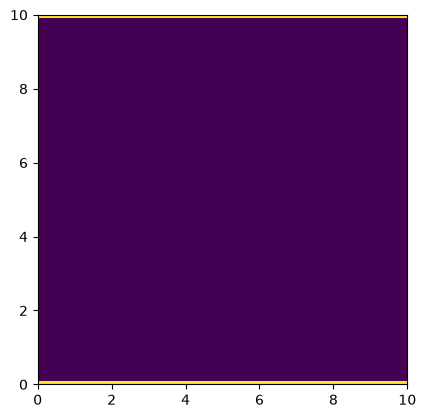

In [13]:
# physical parameters
rho = 1000 # kgm^-3
nu = 0.001/rho # Pa s / kgm^-3


Nx, Ny = 101, 101
dx, dy = 0.1, 0.1 # m

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy

Lx = x[-1]
Ly = y[-1]

X, Y = np.meshgrid(x, y, indexing="ij")

p = np.zeros_like(X)

p_exact = np.cos(np.pi * X / Lx) * np.cos(np.pi * Y / Ly)

f = -((np.pi / Lx) ** 2 + (np.pi / Ly) ** 2) * p_exact

solver = NavierStokesSolver(
    Pmax=1, p=p, u=None, v=None, nu=nu, rho=rho, Lx=Lx, Ly=Ly, Nx=Nx, Ny=Ny
    )


boundary_mesh = np.zeros((Nx, Ny), dtype=bool)
boundary_mesh[:, 0] = False
boundary_mesh[:, -1] = False
boundary_mesh[0, :] = True
boundary_mesh[-1, :] = True

plt.imshow(boundary_mesh, origin="lower", extent=[x[0], x[-1], y[0], y[-1]], aspect="equal")

In [ ]:
# physical parameters
rho = 1000 # kgm^-3
nu = 0.001/rho # Pa s / kgm^-3


Nx, Ny = 101, 101
dx, dy = 0.1, 0.1 # m

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy

Lx = x[-1]
Ly = y[-1]

X, Y = np.meshgrid(x, y, indexing="ij")

p = np.zeros_like(X)

p_exact = np.cos(np.pi * X / Lx) * np.cos(np.pi * Y / Ly)

f = -((np.pi / Lx) ** 2 + (np.pi / Ly) ** 2) * p_exact

solver = NavierStokesSolver(
    Pmax=1, p=p, u=None, v=None, nu=nu, rho=rho, Lx=Lx, Ly=Ly, Nx=Nx, Ny=Ny
    )

In [3]:
p_solve = solver.pressure_poisson_jacobi(RHS=f)

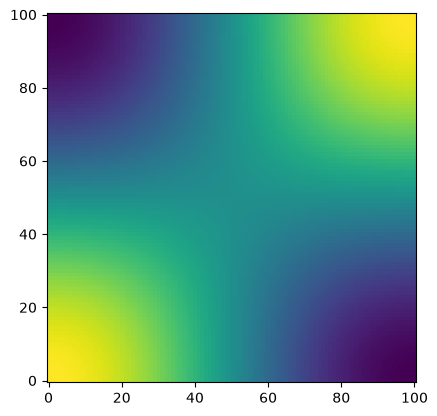

In [4]:
plt.imshow(p_solve, cmap="viridis", origin="lower")

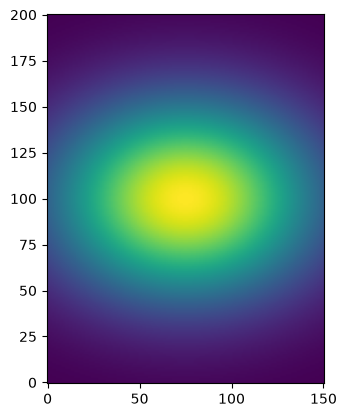

In [ ]:
# physical parameters
rho = 1000 # kgm^-3
nu = 0.001/rho # Pa s / kgm^-3

Nx, Ny = 201, 151
dx, dy = 200, 150

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy

Lx = x[-1]
Ly = y[-1]

X, Y = np.meshgrid(x, y, indexing="ij")

u = np.zeros_like(X)
v = np.zeros_like(X)
p = np.zeros_like(X)

Pmax = 1.0

# Gaussian pressure anomaly
x0 = Lx / 2
y0 = Ly / 2
sigma = min(Lx, Ly) / 3

p = Pmax * np.exp(-((X - x0)**2 + (Y - y0)**2) / (2 * sigma**2))

solver = NavierStokesSolver(
    Pmax=Pmax, p=p, u=u, v=v, nu=nu, rho=rho, Lx=Lx, Ly=Ly, Nx=Nx, Ny=Ny, logs=True
    )

plt.imshow(p, cmap="viridis", origin="lower")

In [6]:
u, v, p_solve = solver.solve_NS(t_end=0.1, output=True, output_freq=100)


Time = 0.00000008
PPE solve iterations = 14263
velocity residual = 0.0
Flow achieved steady state at t = 0.00s
velocity residual = 0.0
norm(u) = 0.00000000, norm(v) = 0.00000000
Courant number: 0.00000000


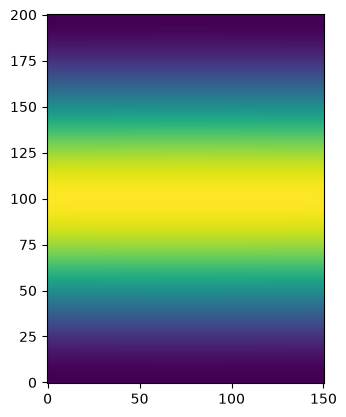

In [7]:
plt.imshow(p_solve, cmap="viridis", origin="lower")